In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/insurance_claims_regression.csv")
df

,fraud_flag,days_until_settlement,claim_amount_k,claim_amount_k.1,num_previous_claims,claim_amount_k.2,claim_amount_k.3,policy_type,policy_holder_age,claim_id
0,0.0,76.0,NaN,NaN,2.0,NaN,NaN,Auto,69.0,C110000
1,NaN,118.0,103.70,103.70,0.0,103.70,103.70,ealth,76.0,C110001
2,0.0,24.0,147.67,147.67,0.0,147.67,147.67,Home,21.0,C110002
3,0.0,80.0,175.88,175.88,2.0,175.88,175.88,Auto,57.0,C110003
4,0.0,8.0,158.71,158.71,1.0,158.71,158.71,NaN,24.0,NaN
...,...,...,...,...,...,...,...,...,...,...
255,NaN,122.0,20.97,20.97,0.0,20.97,20.97,NaN,43.0,C110019
256,NaN,151.0,158.98,158.98,NaN,158.98,158.98,Life,50.0,C110072
257,0.0,34.0,41.83,41.83,2.0,41.83,41.83,HOME,81.0,C110232
258,0.0,36.0,119.72,119.72,4.0,119.72,119.72,Life,59.0,C110163


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   fraud_flag             227 non-null    float64
 1   days_until_settlement  237 non-null    float64
 2   claim_amount_k         237 non-null    float64
 3   claim_amount_k.1       237 non-null    float64
 4   num_previous_claims    237 non-null    float64
 5   claim_amount_k.2       237 non-null    float64
 6   claim_amount_k.3       237 non-null    float64
 7   policy_type            232 non-null    object 
 8   policy_holder_age      236 non-null    float64
 9   claim_id               236 non-null    object 
dtypes: float64(8), object(2)
memory usage: 20.4+ KB


In [4]:
df.isnull().sum()

,0
fraud_flag,33
days_until_settlement,23
claim_amount_k,23
claim_amount_k.1,23
num_previous_claims,23
claim_amount_k.2,23
claim_amount_k.3,23
policy_type,28
policy_holder_age,24
claim_id,24


## Data Cleaning and Preproccesing

In [5]:
df.duplicated().sum()

np.int64(10)

In [6]:
print(df.shape)
print(df.info())
print(df.describe())

(260, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   fraud_flag             227 non-null    float64
 1   days_until_settlement  237 non-null    float64
 2   claim_amount_k         237 non-null    float64
 3   claim_amount_k.1       237 non-null    float64
 4   num_previous_claims    237 non-null    float64
 5   claim_amount_k.2       237 non-null    float64
 6   claim_amount_k.3       237 non-null    float64
 7   policy_type            232 non-null    object 
 8   policy_holder_age      236 non-null    float64
 9   claim_id               236 non-null    object 
dtypes: float64(8), object(2)
memory usage: 20.4+ KB
None
       fraud_flag  days_until_settlement  claim_amount_k  claim_amount_k.1  \
count  227.000000             237.000000      237.000000        237.000000   
mean     0.026432              88.008439       

In [7]:
print("Duplicate Rows:")
print(df.duplicated().sum())

Duplicate Rows:
10


In [8]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (250, 10)


In [9]:
print(df.T.duplicated())

fraud_flag               False
days_until_settlement    False
claim_amount_k           False
claim_amount_k.1          True
num_previous_claims      False
claim_amount_k.2          True
claim_amount_k.3          True
policy_type              False
policy_holder_age        False
claim_id                 False
dtype: bool


In [10]:
df = df.loc[:, ~df.T.duplicated()]

print("Shape after removing duplicate columns:", df.shape)
print(df.columns)

Shape after removing duplicate columns: (250, 7)
Index(['fraud_flag', 'days_until_settlement', 'claim_amount_k',
       'num_previous_claims', 'policy_type', 'policy_holder_age', 'claim_id'],
      dtype='object')


In [11]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
fraud_flag               29
days_until_settlement    22
claim_amount_k           22
num_previous_claims      22
policy_type              25
policy_holder_age        24
claim_id                 24
dtype: int64

Total Missing Values:
168


In [12]:
missing = df.isnull().sum()

percentage = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing,
    'Percentage': percentage
})

print(missing_table)

                       Missing Values  Percentage
fraud_flag                         29        11.6
days_until_settlement              22         8.8
claim_amount_k                     22         8.8
num_previous_claims                22         8.8
policy_type                        25        10.0
policy_holder_age                  24         9.6
claim_id                           24         9.6


In [13]:
num_cols = [
    'days_until_settlement',
    'claim_amount_k',
    'num_previous_claims',
    'policy_holder_age'
]

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

print(df[num_cols].isnull().sum())

days_until_settlement    0
claim_amount_k           0
num_previous_claims      0
policy_holder_age        0
dtype: int64


In [14]:
df['policy_type'] = df['policy_type'].fillna(df['policy_type'].mode()[0])

print(df['policy_type'].isnull().sum())

0


In [15]:
print(df.isnull().sum())
print("Total Missing Values:", df.isnull().sum().sum())

fraud_flag               29
days_until_settlement     0
claim_amount_k            0
num_previous_claims       0
policy_type               0
policy_holder_age         0
claim_id                 24
dtype: int64
Total Missing Values: 53


In [16]:
# Check fraud_flag distribution
print("Fraud Flag Distribution:")
print(df['fraud_flag'].value_counts(dropna=False))

# Check missing rows
print("\nMissing fraud_flag rows:", df['fraud_flag'].isnull().sum())
print("Missing claim_id rows:", df['claim_id'].isnull().sum())

# Display rows where fraud_flag is missing
print("\nRows with missing fraud_flag:")
print(df[df['fraud_flag'].isnull()].head())

Fraud Flag Distribution:
fraud_flag
0.0    215
NaN     29
1.0      6
Name: count, dtype: int64

Missing fraud_flag rows: 29
Missing claim_id rows: 24

Rows with missing fraud_flag:
    fraud_flag  days_until_settlement  claim_amount_k  num_previous_claims  \
1          NaN                  118.0          103.70                  0.0   
6          NaN                   90.0          140.51                  2.0   
19         NaN                  122.0           20.97                  0.0   
24         NaN                    4.0          133.83                  0.0   
26         NaN                   19.0          160.36                  1.0   

   policy_type  policy_holder_age claim_id  
1        ealth               76.0  C110001  
6       Health               49.0  C110006  
19        Auto               43.0  C110019  
24        Auto               74.0  C110024  
26        HOME               51.5  C110026  


In [17]:
# Remove rows with missing target values
df = df.dropna(subset=['fraud_flag'])

print("Shape after removing missing fraud_flag:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Shape after removing missing fraud_flag:
(221, 7)

Missing Values:
fraud_flag                0
days_until_settlement     0
claim_amount_k            0
num_previous_claims       0
policy_type               0
policy_holder_age         0
claim_id                 22
dtype: int64

Total Missing Values:
22


In [18]:
# Remove unnecessary ID column
df = df.drop('claim_id', axis=1)

print("Shape after removing claim_id:")
print(df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Shape after removing claim_id:
(221, 6)

Remaining Missing Values:
fraud_flag               0
days_until_settlement    0
claim_amount_k           0
num_previous_claims      0
policy_type              0
policy_holder_age        0
dtype: int64

Total Missing Values:
0


In [19]:
# Check unique categories
print("Policy Type Categories:")
print(df['policy_type'].unique())

# Count each category
print("\nPolicy Type Counts:")
print(df['policy_type'].value_counts())

Policy Type Categories:
['Auto' 'Home' 'Lif' 'Life' 'Health' 'HOME' 'Hom' 'HEALTH' 'Hme' 'AUTO'
 'LIFE' 'uto' 'Lie' 'Auo' 'Aut' 'Healh' 'Ato' 'ealth' 'Hoe' 'ome']

Policy Type Counts:
policy_type
Auto      64
Home      39
Health    32
Life      27
AUTO      13
LIFE      11
HOME      10
Hme        4
HEALTH     4
Lif        3
Lie        3
Hom        2
uto        2
Auo        1
Aut        1
Healh      1
Ato        1
ealth      1
Hoe        1
ome        1
Name: count, dtype: int64


In [20]:
# Correct policy type names
df['policy_type'] = df['policy_type'].replace({
    'AUTO': 'Auto',
    'uto': 'Auto',
    'Auo': 'Auto',
    'Aut': 'Auto',
    'Ato': 'Auto',

    'HOME': 'Home',
    'Hme': 'Home',
    'Hom': 'Home',
    'Hoe': 'Home',
    'ome': 'Home',

    'LIFE': 'Life',
    'Lif': 'Life',
    'Lie': 'Life',

    'HEALTH': 'Health',
    'Healh': 'Health',
    'ealth': 'Health'
})

print("Cleaned Policy Types:")
print(df['policy_type'].unique())

print("\nPolicy Type Counts:")
print(df['policy_type'].value_counts())

Cleaned Policy Types:
['Auto' 'Home' 'Life' 'Health']

Policy Type Counts:
policy_type
Auto      82
Home      57
Life      44
Health    38
Name: count, dtype: int64


In [21]:
print("Unique Policy Types:")
print(df['policy_type'].unique())

print("\nPolicy Type Counts:")
print(df['policy_type'].value_counts())

print("\nData Types:")
print(df.dtypes)

Unique Policy Types:
['Auto' 'Home' 'Life' 'Health']

Policy Type Counts:
policy_type
Auto      82
Home      57
Life      44
Health    38
Name: count, dtype: int64

Data Types:
fraud_flag               float64
days_until_settlement    float64
claim_amount_k           float64
num_previous_claims      float64
policy_type               object
policy_holder_age        float64
dtype: object


In [22]:
print(df)

     fraud_flag  days_until_settlement  claim_amount_k  num_previous_claims  \
0           0.0                   76.0          96.165                  2.0   
2           0.0                   24.0         147.670                  0.0   
3           0.0                   80.0         175.880                  2.0   
4           0.0                    8.0         158.710                  1.0   
5           0.0                   91.0         138.500                  1.0   
..          ...                    ...             ...                  ...   
245         0.0                  178.0         181.030                  2.0   
246         0.0                   81.0          60.250                  2.0   
247         0.0                  177.0          11.820                  0.0   
248         0.0                   27.0         183.400                  0.0   
249         0.0                   90.0          66.430                  4.0   

    policy_type  policy_holder_age  
0          Aut

In [23]:
df

,fraud_flag,days_until_settlement,claim_amount_k,num_previous_claims,policy_type,policy_holder_age
0,0.0,76.0,96.165,2.0,Auto,69.0
2,0.0,24.0,147.670,0.0,Home,21.0
3,0.0,80.0,175.880,2.0,Auto,57.0
4,0.0,8.0,158.710,1.0,Auto,24.0
5,0.0,91.0,138.500,1.0,Life,55.0
...,...,...,...,...,...,...
245,0.0,178.0,181.030,2.0,Home,78.0
246,0.0,81.0,60.250,2.0,Auto,85.0
247,0.0,177.0,11.820,0.0,Auto,47.0
248,0.0,27.0,183.400,0.0,Home,79.0


# Exploratory Data Analysis

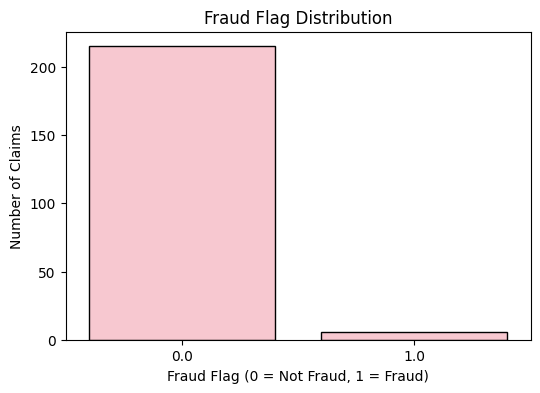

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='fraud_flag',color="pink",edgecolor="black")

plt.title('Fraud Flag Distribution')
plt.xlabel('Fraud Flag (0 = Not Fraud, 1 = Fraud)')
plt.ylabel('Number of Claims')

plt.show()

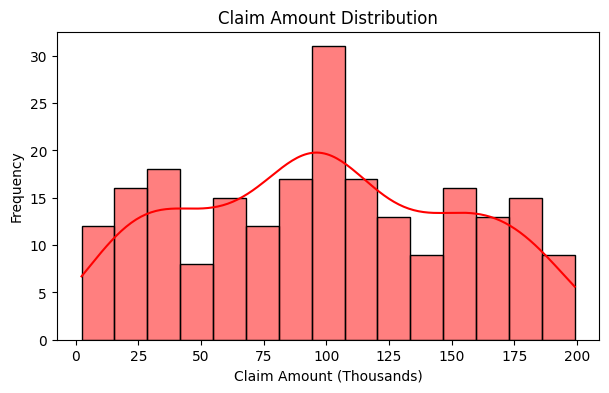

In [25]:
plt.figure(figsize=(7, 4))

sns.histplot(data=df, x='claim_amount_k', bins=15, kde=True,color="red",edgecolor="black")

plt.title('Claim Amount Distribution')
plt.xlabel('Claim Amount (Thousands)')
plt.ylabel('Frequency')

plt.show()

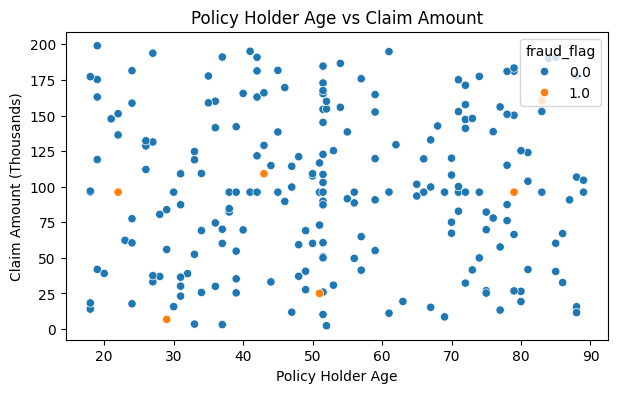

In [26]:
plt.figure(figsize=(7, 4))

sns.scatterplot(
    data=df,
    x='policy_holder_age',
    y='claim_amount_k',
    hue='fraud_flag'
)

plt.title('Policy Holder Age vs Claim Amount')
plt.xlabel('Policy Holder Age')
plt.ylabel('Claim Amount (Thousands)')

plt.show()

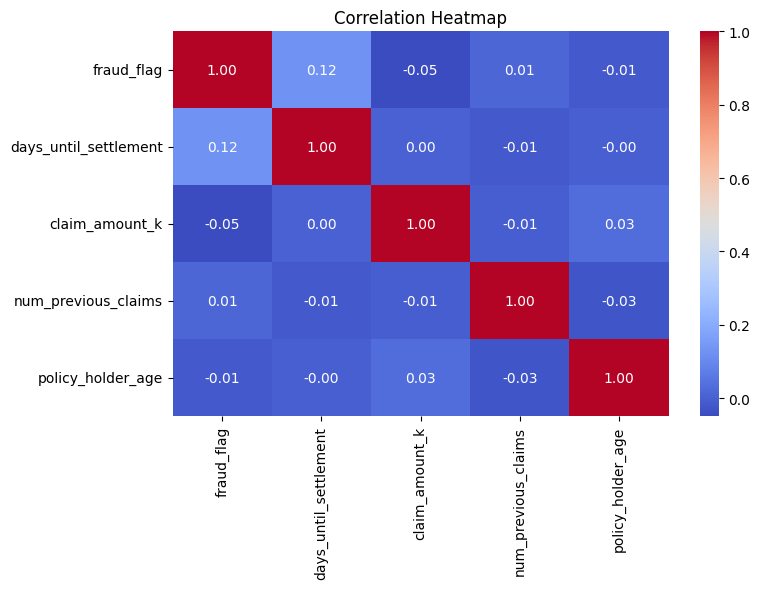

In [27]:
plt.figure(figsize=(8, 5))

corr = df.select_dtypes(include='number').corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

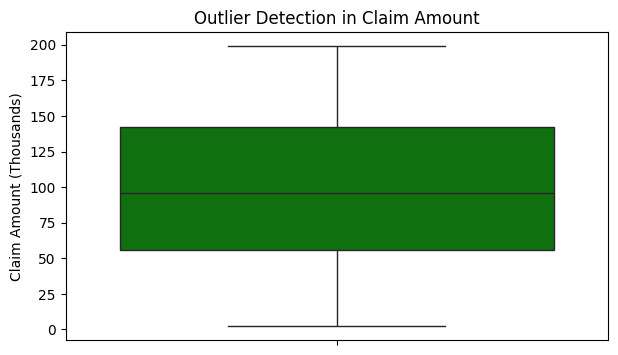

In [28]:
plt.figure(figsize=(7, 4))

sns.boxplot(y=df['claim_amount_k'],color="Green")

plt.title('Outlier Detection in Claim Amount')
plt.ylabel('Claim Amount (Thousands)')

plt.show()

In [29]:
# Calculate Q1 and Q3
Q1 = df['claim_amount_k'].quantile(0.25)
Q3 = df['claim_amount_k'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Identify outliers
outliers = df[
    (df['claim_amount_k'] < lower) |
    (df['claim_amount_k'] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Number of Outliers:", len(outliers))

Q1: 55.92
Q3: 142.16
IQR: 86.24
Lower Limit: -73.43999999999998
Upper Limit: 271.52
Number of Outliers: 0


In [30]:
num_cols = [
    'days_until_settlement',
    'claim_amount_k',
    'num_previous_claims',
    'policy_holder_age'
]

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(col, ":", len(outliers), "outliers")

days_until_settlement : 0 outliers
claim_amount_k : 0 outliers
num_previous_claims : 0 outliers
policy_holder_age : 0 outliers


In [31]:
# Save cleaned dataset
df.to_csv('insurance_claims_cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")

print("\nFinal Dataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

Cleaned dataset saved successfully!

Final Dataset Shape:
(221, 6)

Missing Values:
0
